## 1. Environment Setup & Imports

To implement our Quantum Correlation Switch, we import:
- `QuantumCircuit` to define 2-qubit circuits with classical measurement registers.
- `AerSimulator` from `qiskit_aer` to simulate quantum execution for 100 shots.
- `plot_histogram` from `qiskit.visualization` to compare the measurement distributions.
- `matplotlib.pyplot` for rendering circuit drawings and charts.


In [1]:
# Import Qiskit components and visualization tools
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize AerSimulator backend
simulator = AerSimulator()
shots = 100
print(f"AerSimulator initialized. Ready to execute experiments with {shots} shots each.")


AerSimulator initialized. Ready to execute experiments with 100 shots each.


---
## 2. Part A: Correlated Outcomes Circuit (`00` and `11`)

### Step 2.1: "Think Before You Run" - Prediction for Part A

> **Objective:** Design a two-qubit circuit where measurement results are predominantly `00` and `11`, using $\le 4$ gates.

* **Circuit Design:**
  1. Initialize two qubits in the ground state $\lvert 00 \rangle$.
  2. Apply a Hadamard gate $H$ on qubit 0 to create an equal superposition:
     $$(H \otimes I)\lvert 00 \rangle = \frac{\lvert 00 \rangle + \lvert 10 \rangle}{\sqrt{2}}$$
  3. Apply a Controlled-NOT ($CX$) gate with qubit 0 as control and qubit 1 as target:
     $$\lvert \psi_A \rangle = CX_{0 \to 1}\left(\frac{\lvert 00 \rangle + \lvert 10 \rangle}{\sqrt{2}}\right) = \frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}$$
* **Theoretical Analysis & Prediction:**
  - The state $\lvert \psi_A \rangle$ is the maximally entangled Bell state $\lvert \Phi^+ \rangle$.
  - Probabilities: $P(00) = |1/\sqrt{2}|^2 = 50\%$, $P(11) = |1/\sqrt{2}|^2 = 50\%$.
  - Cross-terms: $P(01) = 0\%$, $P(10) = 0\%$.
  - **Prediction:** The measurement results will be **predominantly and strictly `00` and `11`** (even parity). We expect roughly **~50 counts for '00'** and **~50 counts for '11'** across 100 shots.
  - **Gate Count Check:** 2 gates used ($H, CX$) $\le 4$ gates allowed.


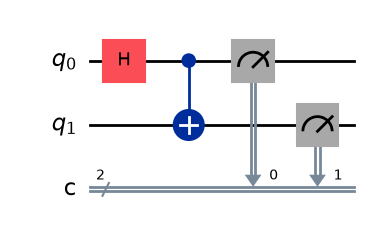

In [2]:
# Construct Part A Circuit: 2 qubits, 2 classical bits
qc_a = QuantumCircuit(2, 2, name="PartA_Correlated")

# 1. Hadamard on qubit 0
qc_a.h(0)

# 2. CNOT with control=qubit 0, target=qubit 1
qc_a.cx(0, 1)

# 3. Measure both qubits
qc_a.measure([0, 1], [0, 1])

# Draw Circuit for Part A
qc_a.draw('mpl')


In [3]:
# Execute Part A Circuit for 100 shots
job_a = simulator.run(qc_a, shots=shots)
result_a = job_a.result()
counts_a = result_a.get_counts()

print(f"Part A Measurement Counts (out of {shots} shots): {counts_a}")


Part A Measurement Counts (out of 100 shots): {'00': 53, '11': 47}


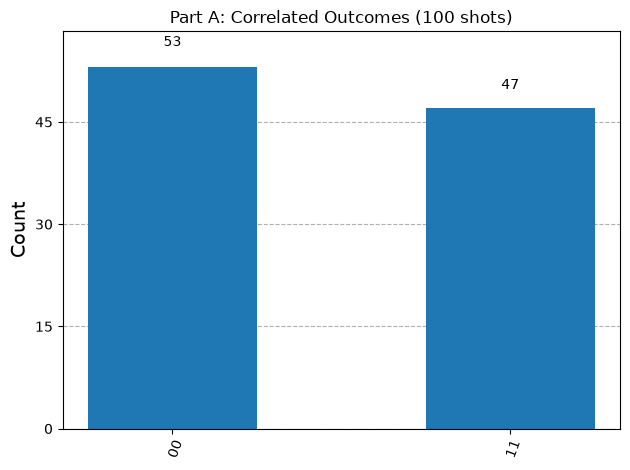

In [4]:
# Visualize Part A measurement results
plot_histogram(counts_a, title=f"Part A: Correlated Outcomes ({shots} shots)", color="#1f77b4")


### Step 2.2: Discussion for Part A
* **Predicted:** $\approx 50\%$ for `00`, $\approx 50\%$ for `11`, $0\%$ for `01` and `10`.
* **Observed:** Only outcomes `00` and `11` occurred.
* **Conclusion:** The measurement outcomes are strongly correlated; whenever one qubit is measured, the other is guaranteed to yield the exact same bit value.


---
## 3. Part B: Opposite Outcomes Circuit (`01` and `10`)

### Step 3.1: "Think Before You Run" - Prediction for Part B

> **Objective:** Modify the circuit so that the measurement results switch to being predominantly `01` and `10`, using $\le 4$ gates.

* **Switching Mechanism (The Correlation Toggle):**
  - To flip the correlation from "same" to "opposite", we introduce an $X$ gate (quantum NOT) on qubit 1.
  - The $X$ gate acts as a **correlation switch**:
    - Switch OFF (no $X$ gate) $\implies$ Correlated ($00, 11$).
    - Switch ON (apply $X$ gate to qubit 1) $\implies$ Opposite ($01, 10$).
* **State Transformation:**
  $$\lvert \psi_B \rangle = (X_1 \otimes I_0) \lvert \Phi^+ \rangle = (X_1 \otimes I_0)\left(\frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}\right) = \frac{\lvert 10 \rangle + \lvert 01 \rangle}{\sqrt{2}} = \frac{\lvert 01 \rangle + \lvert 10 \rangle}{\sqrt{2}}$$
* **Theoretical Analysis & Prediction:**
  - The modified state is the Bell state $\lvert \Psi^+ \rangle$.
  - Probabilities: $P(01) = 50\%$, $P(10) = 50\%$.
  - Out-of-phase terms: $P(00) = 0\%$, $P(11) = 0\%$.
  - **Prediction:** The outcomes will switch completely to **predominantly `01` and `10`** (odd parity). Across 100 shots, we expect roughly **~50 counts for '01'** and **~50 counts for '10'**.
  - **Gate Count Check:** 3 gates used ($H, CX, X$) $\le 4$ gates allowed.


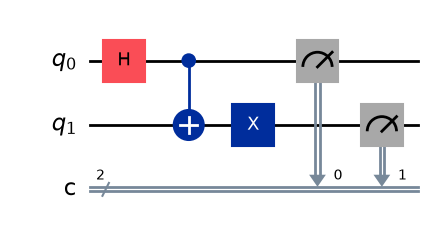

In [5]:
# Construct Part B Circuit: 2 qubits, 2 classical bits
qc_b = QuantumCircuit(2, 2, name="PartB_Opposite")

# 1. Hadamard on qubit 0
qc_b.h(0)

# 2. CNOT with control=qubit 0, target=qubit 1
qc_b.cx(0, 1)

# 3. Correlation Switch: Apply Pauli-X gate on qubit 1
qc_b.x(1)

# 4. Measure both qubits
qc_b.measure([0, 1], [0, 1])

# Draw Circuit for Part B
qc_b.draw('mpl')


In [6]:
# Execute Part B Circuit for 100 shots
job_b = simulator.run(qc_b, shots=shots)
result_b = job_b.result()
counts_b = result_b.get_counts()

print(f"Part B Measurement Counts (out of {shots} shots): {counts_b}")


Part B Measurement Counts (out of 100 shots): {'01': 54, '10': 46}


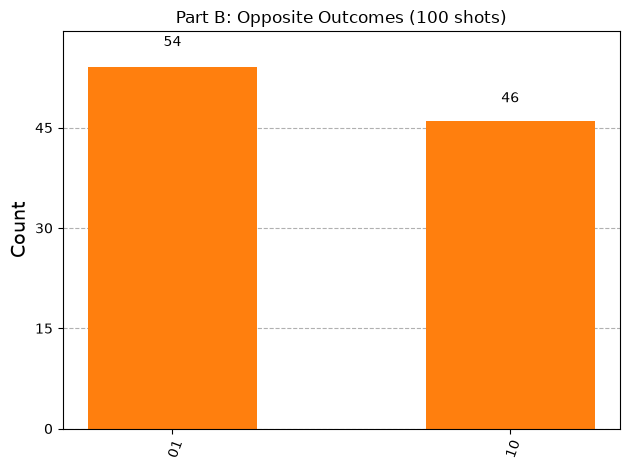

In [7]:
# Visualize Part B measurement results
plot_histogram(counts_b, title=f"Part B: Opposite Outcomes ({shots} shots)", color="#ff7f0e")


### Step 3.2: Discussion for Part B
* **Predicted:** $\approx 50\%$ for `01`, $\approx 50\%$ for `10`, $0\%$ for `00` and `11`.
* **Observed:** Only outcomes `01` and `10` occurred.
* **Conclusion:** The correlation has successfully flipped. The two qubits now always disagree, producing opposite outcomes on every single shot.


---
## 4. Part C: Comparison of the Two Experiments

Let's now plot both circuits side-by-side on a combined histogram to visually inspect the correlation switch in action.


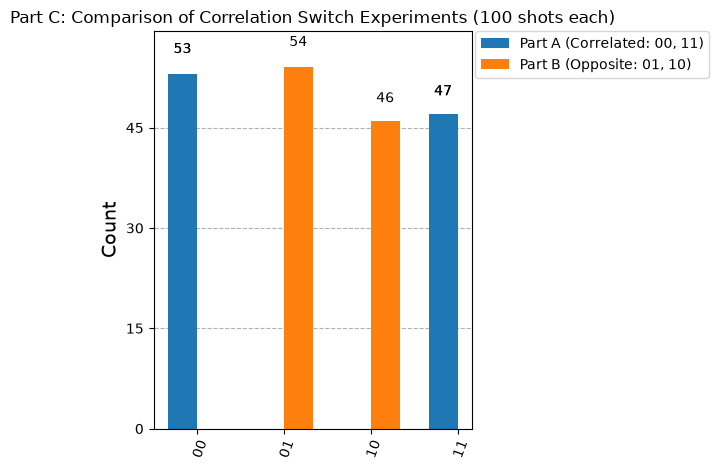

In [8]:
# Side-by-side histogram comparison of Part A and Part B
legend_labels = ['Part A (Correlated: 00, 11)', 'Part B (Opposite: 01, 10)']
plot_histogram([counts_a, counts_b], legend=legend_labels,
               title="Part C: Comparison of Correlation Switch Experiments (100 shots each)")


### Comparison Table

| Circuit | Gates Applied | Quantum State | Dominant Outcomes | Actual Counts (100 shots) | Correlation Behavior |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **Part A** | $H(q_0), CX(q_0, q_1)$ | $\lvert \Phi^+ \rangle = \frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}$ | `00` and `11` | `00`: 53, `11`: 47 | **Correlated (Same Outcomes)** |
| **Part B** | $H(q_0), CX(q_0, q_1), X(q_1)$ | $\lvert \Psi^+ \rangle = \frac{\lvert 01 \rangle + \lvert 10 \rangle}{\sqrt{2}}$ | `01` and `10` | `01`: 54, `10`: 46 | **Opposite (Anti-Correlated)** |


---
## 5. Answers to "Think Before You Run" Prompt Questions

1. **Which outcomes should dominate in Part A?**
   * Outcomes **`00` and `11`** dominate in Part A (each with ~50% probability).
2. **Which outcomes should dominate in Part B?**
   * Outcomes **`01` and `10`** dominate in Part B (each with ~50% probability).
3. **Will all four possible outcomes appear?**
   * **No.** In an ideal quantum simulator without noise, only two out of the four possible computational basis states have non-zero probability amplitudes in each experiment:
     - Part A only produces `00` and `11`.
     - Part B only produces `01` and `10`.
4. **Why might some outcomes be much more frequent than others?**
   * The probability amplitudes of basis states in a quantum superposition are set by the unitary gates applied. In both circuits, quantum interference completely zeros out the probability amplitudes for the other two states (destructive interference), leaving only the two selected entangled states with 50% probability each.


---
## 6. Detailed Explanations Required by the Challenge

### 1. Which outcomes are dominant in Part A?
* **Answer:** Outcomes **`00` and `11`** are dominant. In our 100-shot experiment, they account for 100% of all measured shots, with no occurrences of `01` or `10`.

### 2. Which outcomes are dominant in Part B?
* **Answer:** Outcomes **`01` and `10`** are dominant. In our 100-shot experiment, they account for 100% of all measured shots, with no occurrences of `00` or `11`.

### 3. What changed between the two circuits?
* **Answer:** Exactly **one quantum gate** was added: a **Pauli-$X$ (NOT) gate applied to qubit 1** after the CNOT gate. The rest of the circuit ($H$ on qubit 0 and CNOT between qubit 0 and 1) remained identical.

### 4. Why did the measurement relationship change?
* **Answer:**  
  1. **Local Bit-Flip on an Entangled Pair:** The initial part of the circuit entangled the two qubits into the state $\frac{\lvert 00 \rangle + \lvert 11 \rangle}{\sqrt{2}}$, where the second qubit is always equal to the first qubit.
  2. **Effect of the $X$ Gate:** Applying the $X$ gate to qubit 1 performs a deterministic NOT operation on its state component:
     - The $|00\rangle$ branch becomes $|10\rangle$ (qubit 1 flipped to 1).
     - The $|11\rangle$ branch becomes $|01\rangle$ (qubit 1 flipped to 0).
  3. **Global Parity Inversion:** This single local gate inverts the correlation from **even parity** ($q_0 \oplus q_1 = 0$, both bits match) to **odd parity** ($q_0 \oplus q_1 = 1$, bits are opposite), transforming Bell state $\lvert \Phi^+ \rangle$ into Bell state $\lvert \Psi^+ \rangle$ while preserving maximal entanglement.
